In [ ]:
import sys
import platform
import pandas as pd
import numpy as np
import seaborn as sns
import sklearn
import matplotlib.pyplot as plt


print("=== ОКРУЖЕНИЕ ВЫПОЛНЕНИЯ ===")
print("Python:", sys.version)
print("Реализация Python:", platform.python_implementation())
print("Операционная система:", platform.platform())

print("\n=== ВЕРСИИ БИБЛИОТЕК ===")
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("scikit-learn:", sklearn.__version__)


=== ОКРУЖЕНИЕ ВЫПОЛНЕНИЯ ===
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Реализация Python: CPython
Операционная система: Linux-6.6.122+-x86_64-with-glibc2.39

=== ВЕРСИИ БИБЛИОТЕК ===
pandas: 2.2.3
NumPy: 2.1.3
Matplotlib: 3.10.0
Seaborn: 0.13.2
scikit-learn: 1.6.1


In [ ]:
df = pd.read_csv("/content/ЛЛМ данные.csv")

print("Размер таблицы:", df.shape)

print("\nПервые 5 строк:")
display(df.head())

print("\nНазвания столбцов:")
print(df.columns.tolist())

print("\nТипы данных:")
display(df.dtypes.to_frame("Тип данных"))

print("\nОбщая информация:")
df.info()

Размер таблицы: (15000, 14)

Первые 5 строк:


,id,equipment,operating_hours,temperature_c,vibration_mm_s,pressure_bar,load_ratio,operator_log,manual_id,fault_type,severity,required_route,horizon_days,failure_within_30d
0,1,TR-90,890,65.26,1.862,5.421,0.415,"Работа оборудования стабильна, посторонних шум...",MAN-TR-09,normal,low,no_action,11,0
1,2,PN-300,2165,74.85,1.713,5.932,0.773,"Работа оборудования стабильна, посторонних шум...",MAN-PN-04,normal,low,no_action,21,0
2,3,TR-90,799,63.40,3.695,5.421,0.355,"Слышен характерный шум, давление нестабильно, ...",MAN-TR-18,cavitation,low,hydraulic_inspection,10,0
3,4,PN-200,2077,102.58,1.701,5.282,0.646,Зафиксирован устойчивый рост температуры корпу...,MAN-PN-02,overheat,high,thermal_inspection,19,1
4,5,PN-200,1929,77.36,2.417,6.279,0.461,"Работа оборудования стабильна, посторонних шум...",MAN-PN-08,normal,low,no_action,7,0



Названия столбцов:
['id', 'equipment', 'operating_hours', 'temperature_c', 'vibration_mm_s', 'pressure_bar', 'load_ratio', 'operator_log', 'manual_id', 'fault_type', 'severity', 'required_route', 'horizon_days', 'failure_within_30d']

Типы данных:


,Тип данных
id,int64
equipment,object
operating_hours,int64
temperature_c,float64
vibration_mm_s,float64
pressure_bar,float64
load_ratio,float64
operator_log,object
manual_id,object
fault_type,object



Общая информация:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  15000 non-null  int64  
 1   equipment           15000 non-null  object 
 2   operating_hours     15000 non-null  int64  
 3   temperature_c       15000 non-null  float64
 4   vibration_mm_s      15000 non-null  float64
 5   pressure_bar        15000 non-null  float64
 6   load_ratio          15000 non-null  float64
 7   operator_log        15000 non-null  object 
 8   manual_id           15000 non-null  object 
 9   fault_type          15000 non-null  object 
 10  severity            15000 non-null  object 
 11  required_route      15000 non-null  object 
 12  horizon_days        15000 non-null  int64  
 13  failure_within_30d  15000 non-null  int64  
dtypes: float64(4), int64(4), object(6)
memory usage: 1.6+ MB


In [ ]:
# 1. Проверка пропусков
print("Пропуски")
missing = df.isnull().sum().to_frame("Количество пропусков")
missing["Доля, %"] = (missing["Количество пропусков"] / len(df) * 100).round(2)
display(missing)

# 2. Проверка полных дубликатов
print("Дубликаты")
print("Полных дубликатов:", df.duplicated().sum())
print("Дубликатов по id:", df["id"].duplicated().sum())
print("Уникальных id:", df["id"].nunique())

# 3. Проверка уникальных значений категориальных столбцов
print("Категориальные признаки")
cat_cols = df.select_dtypes(include="object").columns

for col in cat_cols:
    print(f"\n{col}: {df[col].nunique()} уникальных значений")
    print(df[col].value_counts().head(15))

# 4. Проверка бинарной целевой переменной
print("FAILURE_WITHIN_30D")
print(df["failure_within_30d"].value_counts(dropna=False))
print("\nДоли классов, %:")
print((df["failure_within_30d"].value_counts(normalize=True, dropna=False) * 100).round(2))

Пропуски


,Количество пропусков,"Доля, %"
id,0,0.0
equipment,0,0.0
operating_hours,0,0.0
temperature_c,0,0.0
vibration_mm_s,0,0.0
pressure_bar,0,0.0
load_ratio,0,0.0
operator_log,0,0.0
manual_id,0,0.0
fault_type,0,0.0


Дубликаты
Полных дубликатов: 0
Дубликатов по id: 0
Уникальных id: 15000
Категориальные признаки

equipment: 6 уникальных значений
equipment
PN-200    2553
PN-300    2524
CM-110    2518
FV-40     2516
TR-90     2487
CP-500    2402
Name: count, dtype: int64

operator_log: 396 уникальных значений
operator_log
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 74%.    128
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 47%.    125
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 86%.    124
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 44%.    120
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 92%.    119
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 75%.    118
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 98%.    118
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 91%.    115
Работа оборудования стабильна, посторонних шумов нет. Нагрузка 60%.    114
Работа оборудован

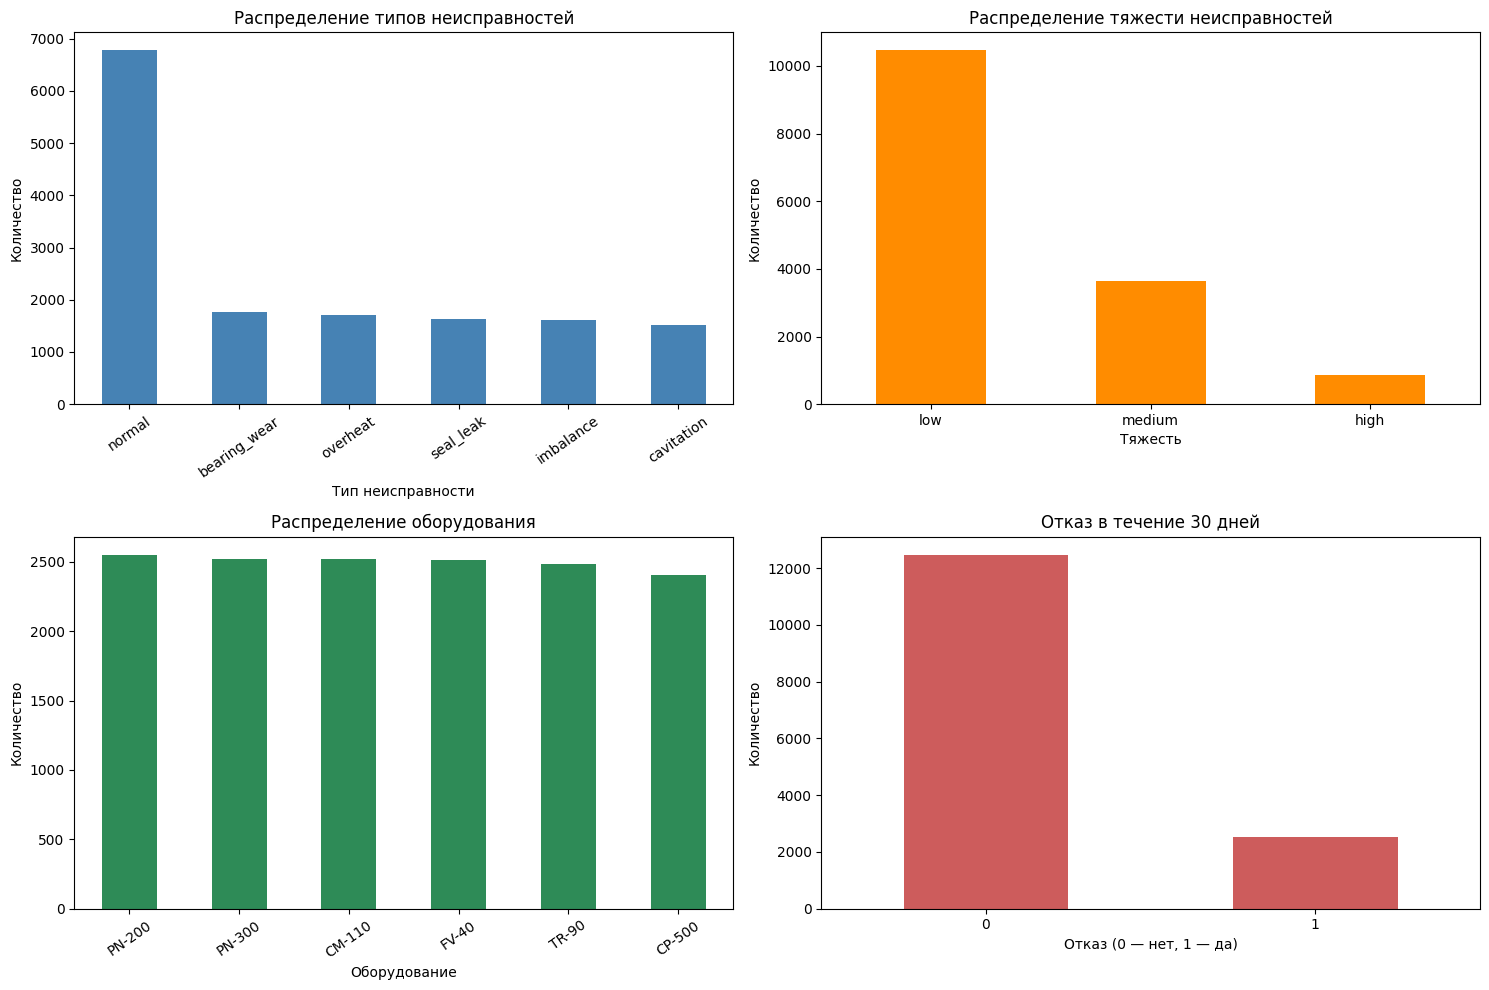

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Тип неисправности
df["fault_type"].value_counts().plot(
    kind="bar", ax=axes[0, 0], color="steelblue"
)
axes[0, 0].set_title("Распределение типов неисправностей")
axes[0, 0].set_xlabel("Тип неисправности")
axes[0, 0].set_ylabel("Количество")
axes[0, 0].tick_params(axis="x", rotation=35)

# Тяжесть неисправности
df["severity"].value_counts().plot(
    kind="bar", ax=axes[0, 1], color="darkorange"
)
axes[0, 1].set_title("Распределение тяжести неисправностей")
axes[0, 1].set_xlabel("Тяжесть")
axes[0, 1].set_ylabel("Количество")
axes[0, 1].tick_params(axis="x", rotation=0)

# Тип оборудования
df["equipment"].value_counts().plot(
    kind="bar", ax=axes[1, 0], color="seagreen"
)
axes[1, 0].set_title("Распределение оборудования")
axes[1, 0].set_xlabel("Оборудование")
axes[1, 0].set_ylabel("Количество")
axes[1, 0].tick_params(axis="x", rotation=35)

# Отказ в течение 30 дней
df["failure_within_30d"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1, 1], color="indianred"
)
axes[1, 1].set_title("Отказ в течение 30 дней")
axes[1, 1].set_xlabel("Отказ (0 — нет, 1 — да)")
axes[1, 1].set_ylabel("Количество")
axes[1, 1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===


,count,mean,std,min,25%,50%,75%,max
operating_hours,15000.0,1248.951,693.552,30.000,647.000,1246.000,1837.000,2699.000
temperature_c,15000.0,65.059,10.475,39.720,58.540,63.010,68.180,118.760
vibration_mm_s,15000.0,2.973,1.358,0.101,2.007,2.536,3.725,7.929
pressure_bar,15000.0,5.819,1.022,1.572,5.336,5.984,6.510,8.593
load_ratio,15000.0,0.676,0.189,0.350,0.511,0.677,0.840,1.000
horizon_days,15000.0,15.534,8.577,1.000,8.000,16.000,23.000,30.000


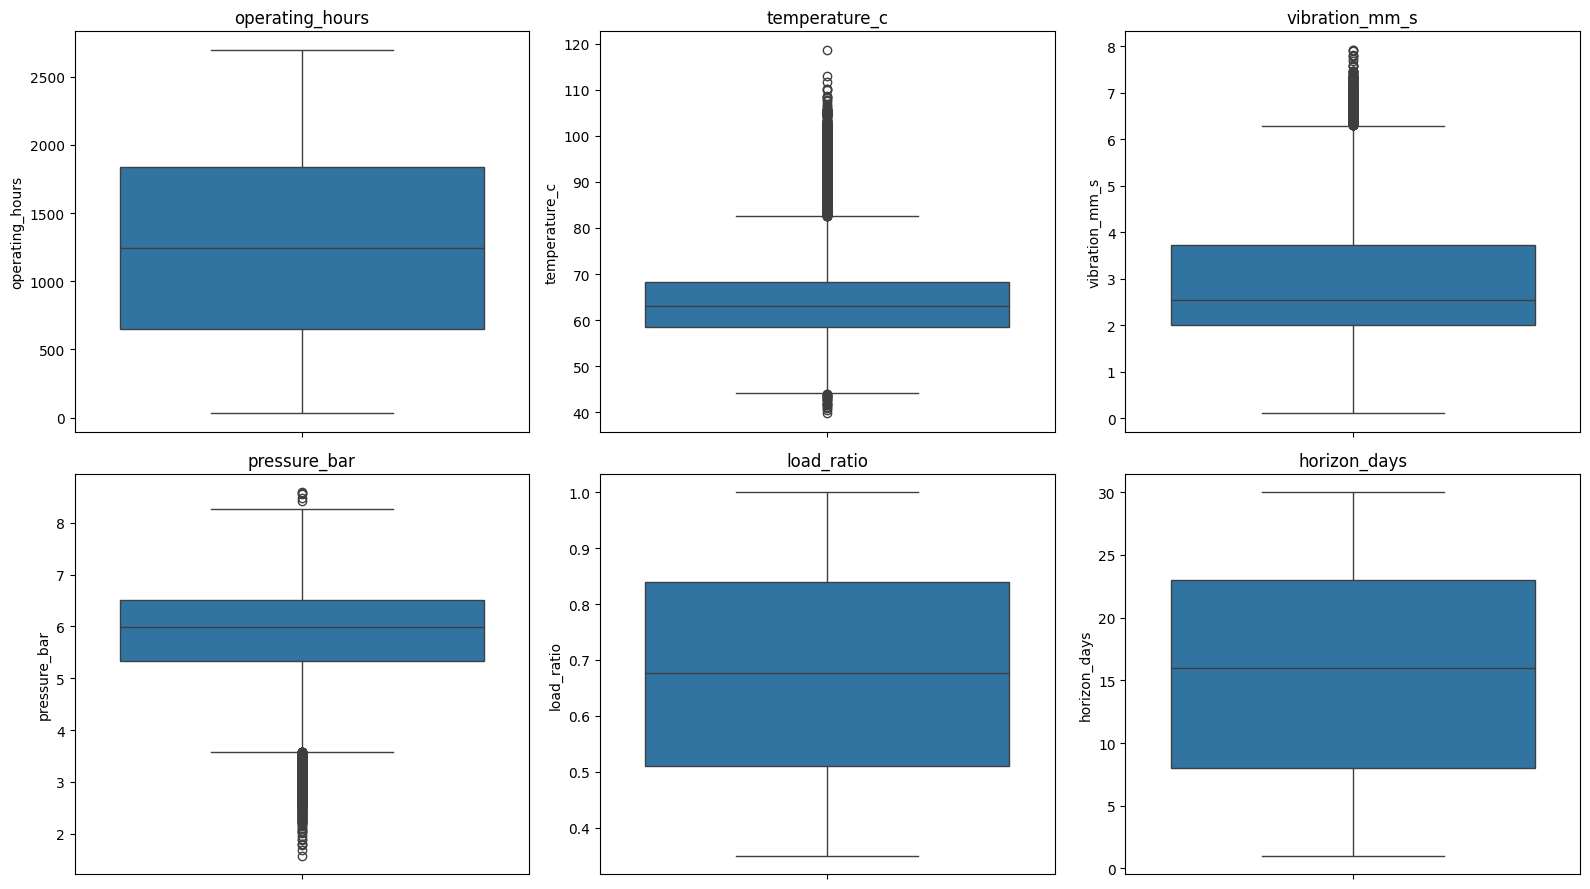

In [ ]:
num_cols = [
    "operating_hours",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio",
    "horizon_days"
]

print("=== ОПИСАТЕЛЬНАЯ СТАТИСТИКА ===")
display(df[num_cols].describe().T.round(3))

# Диаграммы размаха
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for col, ax in zip(num_cols, axes.flat):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

In [ ]:
numeric_cols = [
    "operating_hours",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio",
    "horizon_days"
]

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_results.append({
        "Признак": col,
        "Q1": round(q1, 3),
        "Q3": round(q3, 3),
        "IQR": round(iqr, 3),
        "Нижняя граница": round(lower, 3),
        "Верхняя граница": round(upper, 3),
        "Количество выбросов": int(mask.sum()),
        "Доля выбросов, %": round(mask.mean() * 100, 2),
        "Минимум": round(df[col].min(), 3),
        "Максимум": round(df[col].max(), 3)
    })

outlier_table = pd.DataFrame(outlier_results)
display(outlier_table)


,Признак,Q1,Q3,IQR,Нижняя граница,Верхняя граница,Количество выбросов,"Доля выбросов, %",Минимум,Максимум
0,operating_hours,647.000,1837.000,1190.000,-1138.000,3622.000,0,0.00,30.000,2699.000
1,temperature_c,58.540,68.180,9.640,44.080,82.640,1343,8.95,39.720,118.760
2,vibration_mm_s,2.007,3.725,1.718,-0.570,6.303,349,2.33,0.101,7.929
3,pressure_bar,5.336,6.510,1.174,3.575,8.271,589,3.93,1.572,8.593
4,load_ratio,0.511,0.840,0.329,0.018,1.334,0,0.00,0.350,1.000
5,horizon_days,8.000,23.000,15.000,-14.500,45.500,0,0.00,1.000,30.000


In [ ]:
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(f"\n{'=' * 65}")
    print(f"Признак: {col}")
    print(f"Границы IQR: [{lower:.3f}; {upper:.3f}]")
    print(f"Количество выбросов: {len(outliers)}")

    if len(outliers) > 0:
        display(
            outliers[
                [col, "equipment", "fault_type",
                 "severity", "failure_within_30d"]
            ]
            .sort_values(col)
            .head(10)
        )

        print("Самые высокие значения:")
        display(
            outliers.nlargest(10, col)[
                [col, "equipment", "fault_type",
                 "severity", "failure_within_30d"]
            ]
        )



Признак: operating_hours
Границы IQR: [-1138.000; 3622.000]
Количество выбросов: 0

Признак: temperature_c
Границы IQR: [44.080; 82.640]
Количество выбросов: 1343


,temperature_c,equipment,fault_type,severity,failure_within_30d
11878,39.72,CP-500,normal,low,0
961,40.51,FV-40,seal_leak,medium,1
6471,40.96,CP-500,bearing_wear,high,1
405,41.17,CP-500,normal,low,0
10196,41.46,PN-200,normal,low,0
9611,41.52,TR-90,normal,low,0
8888,41.68,PN-300,cavitation,medium,0
8958,41.83,CM-110,imbalance,low,0
10362,41.98,CM-110,imbalance,medium,0
14054,42.53,FV-40,bearing_wear,high,1


Самые высокие значения:


,temperature_c,equipment,fault_type,severity,failure_within_30d
2785,118.76,PN-200,overheat,high,1
1544,112.99,FV-40,overheat,high,1
7606,111.65,PN-300,overheat,high,1
6935,110.22,CP-500,overheat,high,1
1889,110.20,TR-90,overheat,high,1
13654,109.90,FV-40,overheat,high,1
2392,108.66,FV-40,overheat,high,1
9150,108.42,PN-200,overheat,high,1
749,108.38,FV-40,overheat,high,1
1510,108.17,FV-40,overheat,high,1



Признак: vibration_mm_s
Границы IQR: [-0.570; 6.303]
Количество выбросов: 349


...


Признак: pressure_bar
Границы IQR: [3.575; 8.271]
Количество выбросов: 589


,pressure_bar,equipment,fault_type,severity,failure_within_30d
862,1.572,PN-300,cavitation,high,1
10513,1.693,CM-110,cavitation,high,1
6608,1.789,PN-200,cavitation,high,1
2244,1.804,PN-300,cavitation,high,1
2697,1.812,PN-300,cavitation,high,1
6916,1.878,CM-110,cavitation,high,1
7566,1.905,PN-300,cavitation,high,1
2724,1.958,PN-200,cavitation,high,1
801,2.012,CM-110,cavitation,high,1
11253,2.029,TR-90,cavitation,high,1


Самые высокие значения:


,pressure_bar,equipment,fault_type,severity,failure_within_30d
10126,8.593,FV-40,normal,low,0
705,8.578,FV-40,overheat,medium,0
10061,8.555,CM-110,normal,low,0
11373,8.472,PN-300,normal,low,0
8605,8.413,FV-40,overheat,medium,0
5772,3.575,CM-110,cavitation,medium,1
7932,3.575,CM-110,cavitation,medium,0
1658,3.574,FV-40,cavitation,high,1
9205,3.574,CM-110,cavitation,medium,0
14124,3.573,FV-40,cavitation,medium,0



Признак: load_ratio
Границы IQR: [0.018; 1.333]
Количество выбросов: 0


In [ ]:
failure_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    is_outlier = (df[col] < lower) | (df[col] > upper)

    for group_name, mask in [
        ("Выброс", is_outlier),
        ("Без выброса", ~is_outlier)
    ]:
        part = df.loc[mask]

        failure_results.append({
            "Признак": col,
            "Группа": group_name,
            "Количество наблюдений": len(part),
            "Отказов за 30 дней": int(
                part["failure_within_30d"].sum()
            ),
            "Доля отказов, %": round(
                part["failure_within_30d"].mean() * 100, 2
            ) if len(part) else np.nan
        })

display(pd.DataFrame(failure_results))


,Признак,Группа,Количество наблюдений,Отказов за 30 дней,"Доля отказов, %"
0,operating_hours,Выброс,0,0,NaN
1,operating_hours,Без выброса,15000,2521,16.81
2,temperature_c,Выброс,1343,609,45.35
3,temperature_c,Без выброса,13657,1912,14.00
4,vibration_mm_s,Выброс,349,236,67.62
5,vibration_mm_s,Без выброса,14651,2285,15.60
6,pressure_bar,Выброс,589,491,83.36
7,pressure_bar,Без выброса,14411,2030,14.09
8,load_ratio,Выброс,0,0,NaN
9,load_ratio,Без выброса,15000,2521,16.81


In [ ]:
# Исследуем выбросы по типам неисправностей и оборудованию
for col in ["temperature_c", "vibration_mm_s", "pressure_bar"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    df[f"{col}_outlier"] = (
        (df[col] < lower) | (df[col] > upper)
    )

    print(f"\n--- {col} ---")
    print("\nПо типу неисправности:")
    display(
        df.groupby("fault_type")
        .agg(
            observations=("id", "size"),
            outliers=(f"{col}_outlier", "sum"),
            failure_rate=("failure_within_30d", "mean")
        )
        .assign(
            outlier_pct=lambda x: (
                x["outliers"] / x["observations"] * 100
            ).round(2),
            failure_rate_pct=lambda x: (
                x["failure_rate"] * 100
            ).round(2)
        )
        [["observations", "outliers",
          "outlier_pct", "failure_rate_pct"]]
        .sort_values("outlier_pct", ascending=False)
    )

    print("\nПо типу оборудования:")
    display(
        df.groupby("equipment")
        .agg(
            observations=("id", "size"),
            outliers=(f"{col}_outlier", "sum")
        )
        .assign(
            outlier_pct=lambda x: (
                x["outliers"] / x["observations"] * 100
            ).round(2)
        )
        .sort_values("outlier_pct", ascending=False)
    )



--- temperature_c ---

По типу неисправности:


,observations,outliers,outlier_pct,failure_rate_pct
fault_type,,,,
overheat,1704,1315,77.17,36.68
imbalance,1607,8,0.50,14.87
bearing_wear,1762,5,0.28,38.25
normal,6784,11,0.16,0.00
cavitation,1511,2,0.13,51.22
seal_leak,1632,2,0.12,12.81



По типу оборудования:


,observations,outliers,outlier_pct
equipment,,,
TR-90,2487,231,9.29
FV-40,2516,231,9.18
CP-500,2402,218,9.08
CM-110,2518,224,8.90
PN-200,2553,222,8.70
PN-300,2524,217,8.60



--- vibration_mm_s ---

По типу неисправности:


...

,observations,outliers,outlier_pct
equipment,,,
CP-500,2402,62,2.58
CM-110,2518,64,2.54
TR-90,2487,61,2.45
FV-40,2516,61,2.42
PN-200,2553,54,2.12
PN-300,2524,47,1.86



--- pressure_bar ---

По типу неисправности:


,observations,outliers,outlier_pct,failure_rate_pct
fault_type,,,,
cavitation,1511,541,35.80,51.22
seal_leak,1632,43,2.63,12.81
overheat,1704,2,0.12,36.68
normal,6784,3,0.04,0.00
bearing_wear,1762,0,0.00,38.25
imbalance,1607,0,0.00,14.87



По типу оборудования:


,observations,outliers,outlier_pct
equipment,,,
PN-300,2524,111,4.40
CM-110,2518,105,4.17
PN-200,2553,101,3.96
TR-90,2487,98,3.94
FV-40,2516,90,3.58
CP-500,2402,84,3.50


In [ ]:
for col in ["temperature_c", "vibration_mm_s", "pressure_bar"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_mask = df[col] < lower
    high_mask = df[col] > upper

    print(f"\n--- {col} ---")
    print("Ниже нижней границы:", int(low_mask.sum()))
    print("Выше верхней границы:", int(high_mask.sum()))

    for label, mask in [
        ("Ниже границы", low_mask),
        ("Выше границы", high_mask)
    ]:
        if mask.sum() > 0:
            print(f"\n{label}:")
            display(
                df.loc[mask]
                .groupby("fault_type")
                .agg(
                    observations=("id", "size"),
                    failure_rate=("failure_within_30d", "mean")
                )
                .assign(
                    failure_rate_pct=lambda x:
                        (x["failure_rate"] * 100).round(2)
                )
                [["observations", "failure_rate_pct"]]
                .sort_values("observations", ascending=False)
            )



--- temperature_c ---
Ниже нижней границы: 22
Выше верхней границы: 1321

Ниже границы:


,observations,failure_rate_pct
fault_type,,
normal,9,0.00
imbalance,7,14.29
bearing_wear,3,100.00
cavitation,2,0.00
seal_leak,1,100.00



Выше границы:


,observations,failure_rate_pct
fault_type,,
overheat,1315,45.7
bearing_wear,2,100.0
normal,2,0.0
imbalance,1,100.0
seal_leak,1,0.0



--- vibration_mm_s ---
Ниже нижней границы: 0
Выше верхней границы: 349

Выше границы:


,observations,failure_rate_pct
fault_type,,
bearing_wear,337,68.55
imbalance,12,41.67



--- pressure_bar ---
Ниже нижней границы: 584
Выше верхней границы: 5

Ниже границы:


,observations,failure_rate_pct
fault_type,,
cavitation,541,85.58
seal_leak,43,65.12



Выше границы:


,observations,failure_rate_pct
fault_type,,
normal,3,0.0
overheat,2,0.0


In [ ]:
# 1. Связь типа неисправности с маршрутом обслуживания
print("=== FAULT_TYPE × REQUIRED_ROUTE ===")

display(pd.crosstab(
    df["fault_type"],
    df["required_route"],
    margins=True
))

# Сколько маршрутов встречается у каждого типа неисправности
routes_per_fault = df.groupby("fault_type")["required_route"].nunique()

print("\nКоличество маршрутов для каждого fault_type:")
display(routes_per_fault.to_frame("Количество маршрутов"))

# 2. Связь типа неисправности с тяжестью
print("\n=== FAULT_TYPE × SEVERITY ===")

display(pd.crosstab(
    df["fault_type"],
    df["severity"],
    normalize="index"
).round(3))

# 3. Связь типа неисправности с фактом отказа
print("\n=== FAULT_TYPE × FAILURE_WITHIN_30D ===")

display(pd.crosstab(
    df["fault_type"],
    df["failure_within_30d"],
    normalize="index"
).round(3))

# 4. Проверка, не определяет ли текстовый журнал тип неисправности
print("\n=== OPERATOR_LOG → FAULT_TYPE ===")

text_mapping = df.groupby("operator_log")["fault_type"].nunique()

print("Уникальных текстов журналов:", df["operator_log"].nunique())
print("Текстов, встречающихся с несколькими fault_type:",
      (text_mapping > 1).sum())
print("Текстов, соответствующих только одному fault_type:",
      (text_mapping == 1).sum())

=== FAULT_TYPE × REQUIRED_ROUTE ===


required_route,balancing,bearing_diagnostics,hydraulic_inspection,no_action,seal_repair,thermal_inspection,All
fault_type,,,,,,,
bearing_wear,0,1762,0,0,0,0,1762
cavitation,0,0,1511,0,0,0,1511
imbalance,1607,0,0,0,0,0,1607
normal,0,0,0,6784,0,0,6784
overheat,0,0,0,0,0,1704,1704
seal_leak,0,0,0,0,1632,0,1632
All,1607,1762,1511,6784,1632,1704,15000



Количество маршрутов для каждого fault_type:


,Количество маршрутов
fault_type,
bearing_wear,1
cavitation,1
imbalance,1
normal,1
overheat,1
seal_leak,1



=== FAULT_TYPE × SEVERITY ===


severity,high,low,medium
fault_type,,,
bearing_wear,0.103,0.277,0.620
cavitation,0.302,0.220,0.478
imbalance,0.002,0.663,0.335
normal,0.000,1.000,0.000
overheat,0.123,0.346,0.532
seal_leak,0.016,0.743,0.241



=== FAULT_TYPE × FAILURE_WITHIN_30D ===


failure_within_30d,0,1
fault_type,,
bearing_wear,0.617,0.383
cavitation,0.488,0.512
imbalance,0.851,0.149
normal,1.000,0.000
overheat,0.633,0.367
seal_leak,0.872,0.128



=== OPERATOR_LOG → FAULT_TYPE ===
Уникальных текстов журналов: 396
Текстов, встречающихся с несколькими fault_type: 0
Текстов, соответствующих только одному fault_type: 396


In [ ]:
# Примеры текстовых журналов по каждому типу неисправности
for fault in sorted(df["fault_type"].unique()):
    print(f"\n{'=' * 80}")
    print(f"Тип неисправности: {fault}")

    examples = (
        df.loc[df["fault_type"] == fault, "operator_log"]
        .drop_duplicates()
        .head(5)
    )

    for i, log in enumerate(examples, start=1):
        print(f"{i}. {log}")

# Проверяем, одинаковы ли распределения текстов по классам
print("\n=== ЧИСЛО УНИКАЛЬНЫХ ТЕКСТОВ ПО КЛАССАМ ===")

display(
    df.groupby("fault_type")["operator_log"]
      .nunique()
      .sort_values(ascending=False)
      .to_frame("Уникальных текстов")
)

# Проверяем, насколько тесно связан текст с типом оборудования
print("\n=== ТЕКСТЫ, ВСТРЕЧАЮЩИЕСЯ У НЕСКОЛЬКИХ ТИПОВ ОБОРУДОВАНИЯ ===")

equipment_per_log = df.groupby("operator_log")["equipment"].nunique()

print(
    "Текстов, встречающихся у нескольких типов оборудования:",
    (equipment_per_log > 1).sum()
)


Тип неисправности: bearing_wear
1. Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 70%.
2. Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 50%.
3. Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 48%.
4. Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 75%.
5. Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка 60%.

Тип неисправности: cavitation
1. Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 35%.
2. Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 71%.
3. Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 89%.
4. Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 50%.
5. Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка 91%.

Тип неисправности: imbalance
1. После выхода на режим появилась повышенная вибрация и биение. Нагруз

,Уникальных текстов
fault_type,
bearing_wear,66
cavitation,66
imbalance,66
normal,66
overheat,66
seal_leak,66



=== ТЕКСТЫ, ВСТРЕЧАЮЩИЕСЯ У НЕСКОЛЬКИХ ТИПОВ ОБОРУДОВАНИЯ ===
Текстов, встречающихся у нескольких типов оборудования: 396


In [ ]:
import re

def normalize_log(text):
    # Убираем изменяющееся числовое значение нагрузки
    text = re.sub(r"Нагрузка\s+\d+%", "Нагрузка <LOAD>%", text)
    return text.strip()

df["operator_log_template"] = df["operator_log"].apply(normalize_log)

print("Всего записей:", len(df))
print("Уникальных исходных текстов:", df["operator_log"].nunique())
print("Уникальных шаблонов после нормализации:",
      df["operator_log_template"].nunique())

print("\nКоличество шаблонов на класс:")
display(
    df.groupby("fault_type")["operator_log_template"]
      .nunique()
      .to_frame("Уникальных шаблонов")
)

print("\nСоответствие шаблонов типам неисправностей:")
template_mapping = (
    df.groupby("operator_log_template")
      .agg(
          n_fault_types=("fault_type", "nunique"),
          fault_types=("fault_type", lambda x: ", ".join(sorted(x.unique()))),
          n_records=("id", "size")
      )
      .sort_values("n_records", ascending=False)
)

display(template_mapping.head(20))

print("\nШаблонов, встречающихся с несколькими типами неисправностей:",
      (template_mapping["n_fault_types"] > 1).sum())

Всего записей: 15000
Уникальных исходных текстов: 396
Уникальных шаблонов после нормализации: 6

Количество шаблонов на класс:


,Уникальных шаблонов
fault_type,
bearing_wear,1
cavitation,1
imbalance,1
normal,1
overheat,1
seal_leak,1



Соответствие шаблонов типам неисправностей:


,n_fault_types,fault_types,n_records
operator_log_template,,,
"Работа оборудования стабильна, посторонних шумов нет. Нагрузка <LOAD>%.",1,normal,6784
Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка <LOAD>%.,1,bearing_wear,1762
Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка <LOAD>%.,1,overheat,1704
Обнаружены следы утечки в зоне уплотнения и снижение давления. Нагрузка <LOAD>%.,1,seal_leak,1632
После выхода на режим появилась повышенная вибрация и биение. Нагрузка <LOAD>%.,1,imbalance,1607
"Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка <LOAD>%.",1,cavitation,1511



Шаблонов, встречающихся с несколькими типами неисправностей: 0


In [ ]:

from sklearn.model_selection import train_test_split

SEED = 42

# Сочетаем две целевые переменные,
# чтобы стратифицировать по их комбинациям
joint_strata = (
    df["fault_type"].astype(str)
    + "_"
    + df["failure_within_30d"].astype(str)
)

print("Размеры совместных страт:")
print(joint_strata.value_counts())

# Сначала выделяем 15% на тестовую выборку
train_val_idx, test_idx = train_test_split(
    df.index,
    test_size=0.15,
    random_state=SEED,
    stratify=joint_strata
)

# Затем выделяем 15% от исходного датасета на validation.
# В оставшихся 85% это составляет 0.15 / 0.85.
train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.15 / 0.85,
    random_state=SEED,
    stratify=joint_strata.loc[train_val_idx]
)

train_df = df.loc[train_idx].copy()
val_df = df.loc[val_idx].copy()
test_df = df.loc[test_idx].copy()

print("\nРазмеры выборок:")
print("Train:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Размеры совместных страт:
normal_0          6784
seal_leak_0       1423
imbalance_0       1368
bearing_wear_0    1088
overheat_0        1079
cavitation_1       774
cavitation_0       737
bearing_wear_1     674
overheat_1         625
imbalance_1        239
seal_leak_1        209
Name: count, dtype: int64

Размеры выборок:
Train: 10500
Validation: 2250
Test: 2250


In [ ]:
# 1. Проверяем зависимость id от целевых переменных
print("=== ПРОВЕРКА ID ===")

display(
    df.groupby("fault_type")["id"]
      .agg(["min", "max", "mean"])
      .round(2)
)

# 2. Проверяем связь severity с отказом
print("\n=== SEVERITY × FAILURE_WITHIN_30D ===")

display(
    pd.crosstab(
        df["severity"],
        df["failure_within_30d"],
        normalize="index"
    ).round(3)
)

# 3. Проверяем долю отказов по типу неисправности
print("\n=== ДОЛЯ ОТКАЗОВ ПО FAULT_TYPE ===")

display(
    df.groupby("fault_type")["failure_within_30d"]
      .agg(["count", "sum", "mean"])
      .rename(columns={
          "count": "Количество записей",
          "sum": "Количество отказов",
          "mean": "Доля отказов"
      })
      .sort_values("Доля отказов", ascending=False)
      .round(3)
)

# 4. Проверяем наличие точных копий строк без id
print("\n=== ПОВТОРЫ БЕЗ ID ===")

print(
    "Повторяющихся строк без id:",
    df.drop(columns=["id"]).duplicated().sum()
)

=== ПРОВЕРКА ID ===


,min,max,mean
fault_type,,,
bearing_wear,16,14997,7543.77
cavitation,3,14996,7479.00
imbalance,15,15000,7544.39
normal,1,14999,7490.29
overheat,4,14995,7404.68
seal_leak,13,14975,7572.94



=== SEVERITY × FAILURE_WITHIN_30D ===


failure_within_30d,0,1
severity,,
high,0.00,1.00
low,1.00,0.00
medium,0.55,0.45



=== ДОЛЯ ОТКАЗОВ ПО FAULT_TYPE ===


,Количество записей,Количество отказов,Доля отказов
fault_type,,,
cavitation,1511,774,0.512
bearing_wear,1762,674,0.383
overheat,1704,625,0.367
imbalance,1607,239,0.149
seal_leak,1632,209,0.128
normal,6784,0,0.000



=== ПОВТОРЫ БЕЗ ID ===
Повторяющихся строк без id: 0


In [ ]:
# 1. Пересечение индексов
print("Пересечение индексов:")
print("train / validation:", len(set(train_df.index) & set(val_df.index)))
print("train / test:", len(set(train_df.index) & set(test_df.index)))
print("validation / test:", len(set(val_df.index) & set(test_df.index)))

# 2. Пересечение id
print("\nПересечение id:")
print("train / validation:",
      len(set(train_df["id"]) & set(val_df["id"])))
print("train / test:",
      len(set(train_df["id"]) & set(test_df["id"])))
print("validation / test:",
      len(set(val_df["id"]) & set(test_df["id"])))

# 3. Повторяющиеся записи без технического идентификатора
columns_without_id = [c for c in df.columns if c != "id"]

train_rows = set(
    map(tuple, train_df[columns_without_id].to_numpy())
)
val_rows = set(
    map(tuple, val_df[columns_without_id].to_numpy())
)
test_rows = set(
    map(tuple, test_df[columns_without_id].to_numpy())
)

print("\nСовпадающие строки без id:")
print("train / validation:", len(train_rows & val_rows))
print("train / test:", len(train_rows & test_rows))
print("validation / test:", len(val_rows & test_rows))

Пересечение индексов:
train / validation: 0
train / test: 0
validation / test: 0

Пересечение id:
train / validation: 0
train / test: 0
validation / test: 0

Совпадающие строки без id:
train / validation: 0
train / test: 0
validation / test: 0


In [ ]:
# Проверяем, что нормализованный текст подготовлен
assert "operator_log_template" in df.columns
assert "operator_log_template" in train_df.columns
assert "operator_log_template" in val_df.columns
assert "operator_log_template" in test_df.columns

splits = {
    "train": train_df,
    "validation": val_df,
    "test": test_df
}

# Множества уникальных нормализованных шаблонов
templates = {
    name: set(part["operator_log_template"].dropna())
    for name, part in splits.items()
}

print("=== УНИКАЛЬНЫЕ ШАБЛОНЫ ПО ВЫБОРКАМ ===")

for name, part in splits.items():
    print(
        f"{name}: "
        f"{part['operator_log_template'].nunique()} уникальных шаблонов; "
        f"{part['operator_log_template'].nunique() / len(part):.2%} "
        f"от числа записей"
    )

print("\n=== ПЕРЕСЕЧЕНИЯ ШАБЛОНОВ ===")

pairs = [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]

for a, b in pairs:
    common = templates[a] & templates[b]

    print(f"{a} / {b}: {len(common)} общих шаблонов")

    if common:
        print("Примеры:", list(common)[:3])

# Доля строк, текстовый шаблон которых уже встречался в train
train_templates = templates["train"]

print("\n=== ДОЛЯ ШАБЛОНОВ, УЖЕ ВСТРЕЧАВШИХСЯ В TRAIN ===")

for name in ["train", "validation", "test"]:
    part = splits[name]
    seen = part["operator_log_template"].isin(train_templates)

    print(f"{name}: {seen.mean():.2%} строк")

# Проверяем, соответствует ли шаблон одному типу неисправности
print("\n=== СООТВЕТСТВИЕ ШАБЛОНОВ ЦЕЛЕВОМУ КЛАССУ ===")

template_classes = (
    df.groupby("operator_log_template")
      .agg(
          n_classes=("fault_type", "nunique"),
          classes=("fault_type",
                   lambda x: ", ".join(sorted(x.unique()))),
          n_records=("fault_type", "size")
      )
      .sort_values("n_records", ascending=False)
)

display(template_classes)

print(
    "Шаблонов, связанных с несколькими классами:",
    (template_classes["n_classes"] > 1).sum()
)

=== УНИКАЛЬНЫЕ ШАБЛОНЫ ПО ВЫБОРКАМ ===
train: 6 уникальных шаблонов; 0.06% от числа записей
validation: 6 уникальных шаблонов; 0.27% от числа записей
test: 6 уникальных шаблонов; 0.27% от числа записей

=== ПЕРЕСЕЧЕНИЯ ШАБЛОНОВ ===
train / validation: 6 общих шаблонов
Примеры: ['Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка <LOAD>%.', 'Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка <LOAD>%.', 'Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка <LOAD>%.']
train / test: 6 общих шаблонов
Примеры: ['Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка <LOAD>%.', 'Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка <LOAD>%.', 'Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка <LOAD>%.']
validation / test: 6 общих шаблонов
Примеры: ['Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка <LOAD>%.', 'Слышен характ

,n_classes,classes,n_records
operator_log_template,,,
"Работа оборудования стабильна, посторонних шумов нет. Нагрузка <LOAD>%.",1,normal,6784
Оператор отмечает нарастающий гул в зоне подшипников и вибрацию. Нагрузка <LOAD>%.,1,bearing_wear,1762
Зафиксирован устойчивый рост температуры корпуса при рабочей нагрузке. Нагрузка <LOAD>%.,1,overheat,1704
Обнаружены следы утечки в зоне уплотнения и снижение давления. Нагрузка <LOAD>%.,1,seal_leak,1632
После выхода на режим появилась повышенная вибрация и биение. Нагрузка <LOAD>%.,1,imbalance,1607
"Слышен характерный шум, давление нестабильно, наблюдается вибрация. Нагрузка <LOAD>%.",1,cavitation,1511


Шаблонов, связанных с несколькими классами: 0


In [ ]:

# Признаки для двух задач

# 1. Классификация типа неисправности
features_fault_type = [
    "equipment",
    "operating_hours",
    "horizon_days",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio",
]

# 2. Прогноз отказа в течение 30 дней
features_failure = [
    "equipment",
    "operating_hours",
    "horizon_days",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio",
]

print("Задача 1: классификация неисправности")
print("Целевая переменная: fault_type")
print("Признаки:", features_fault_type)

print("\nЗадача 2: прогноз отказа")
print("Целевая переменная: failure_within_30d")
print("Признаки:", features_failure)

print("\nПроверка доступности признаков:")
display(
    df[features_fault_type + ["fault_type", "failure_within_30d"]].head()
)


Задача 1: классификация неисправности
Целевая переменная: fault_type
Признаки: ['equipment', 'operating_hours', 'horizon_days', 'temperature_c', 'vibration_mm_s', 'pressure_bar', 'load_ratio']

Задача 2: прогноз отказа
Целевая переменная: failure_within_30d
Признаки: ['equipment', 'operating_hours', 'horizon_days', 'temperature_c', 'vibration_mm_s', 'pressure_bar', 'load_ratio']

Проверка доступности признаков:


,equipment,operating_hours,horizon_days,temperature_c,vibration_mm_s,pressure_bar,load_ratio,fault_type,failure_within_30d
0,TR-90,890,11,65.26,1.862,5.421,0.415,normal,0
1,PN-300,2165,21,74.85,1.713,5.932,0.773,normal,0
2,TR-90,799,10,63.40,3.695,5.421,0.355,cavitation,0
3,PN-200,2077,19,102.58,1.701,5.282,0.646,overheat,1
4,PN-200,1929,7,77.36,2.417,6.279,0.461,normal,0


In [ ]:

for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n=== {name} ===")

    print("\nfault_type, %:")
    print(
        (part["fault_type"].value_counts(normalize=True) * 100)
        .round(2)
    )

    print("\nfailure_within_30d, %:")
    print(
        (part["failure_within_30d"].value_counts(normalize=True) * 100)
        .round(2)
    )



=== Train ===

fault_type, %:
fault_type
normal          45.22
bearing_wear    11.75
overheat        11.35
seal_leak       10.89
imbalance       10.71
cavitation      10.08
Name: proportion, dtype: float64

failure_within_30d, %:
failure_within_30d
0    83.19
1    16.81
Name: proportion, dtype: float64

=== Validation ===

fault_type, %:
fault_type
normal          45.24
bearing_wear    11.73
overheat        11.38
seal_leak       10.89
imbalance       10.71
cavitation      10.04
Name: proportion, dtype: float64

failure_within_30d, %:
failure_within_30d
0    83.2
1    16.8
Name: proportion, dtype: float64

=== Test ===

fault_type, %:
fault_type
normal          45.24
bearing_wear    11.73
overheat        11.38
seal_leak       10.84
imbalance       10.71
cavitation      10.09
Name: proportion, dtype: float64

failure_within_30d, %:
failure_within_30d
0    83.2
1    16.8
Name: proportion, dtype: float64


In [ ]:

# Целевые переменные
TARGET_FAULT = "fault_type"
TARGET_FAILURE = "failure_within_30d"

# Числовые признаки
numeric_features = [
    "operating_hours",
    "horizon_days",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio"
]

# Категориальные признаки
categorical_features = [
    "equipment"
]

# Текстовые признаки
text_features = [
    "operator_log"
]

# Проверяем, что признаки существуют
for col in numeric_features + categorical_features + text_features:
    assert col in df.columns, f"Нет столбца: {col}"

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)
print("Текстовые признаки:", text_features)

print("\nРазмеры данных по выборкам:")
for name, part in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(part)} строк; "
        f"numeric={len(numeric_features)}, "
        f"categorical={len(categorical_features)}, "
        f"text={len(text_features)}"
    )


Числовые признаки: ['operating_hours', 'horizon_days', 'temperature_c', 'vibration_mm_s', 'pressure_bar', 'load_ratio']
Категориальные признаки: ['equipment']
Текстовые признаки: ['operator_log']

Размеры данных по выборкам:
Train: 10500 строк; numeric=6, categorical=1, text=1
Validation: 2250 строк; numeric=6, categorical=1, text=1
Test: 2250 строк; numeric=6, categorical=1, text=1


In [ ]:

# ==========================================
# ПОДГОТОВКА НАБОРОВ ПРИЗНАКОВ ДЛЯ ML
# ==========================================

TARGET_FAULT = "fault_type"
TARGET_FAILURE = "failure_within_30d"


def prepare_feature_sets(part):
    return {
        # Числовые
        "numeric_only": part[
            numeric_features].copy(),

        # Текстовые признаки
        "text_only": part[text_features].copy(),

        # Для Transformer используется тот же исходный текст,
        # дальнейшая токенизация выполняется отдельно
        "transformer_only": part[text_features].copy(),

        # Все входные признаки для объединённой модели
        "fusion": part[
            numeric_features
            + categorical_features
            + text_features
        ].copy(),

        # Целевые переменные хранятся отдельно
        "y_fault_type": part[TARGET_FAULT].copy(),
        "y_failure": part[TARGET_FAILURE].copy()
    }


# Создаём отдельные наборы для каждой выборки
train_sets = prepare_feature_sets(train_df)
val_sets = prepare_feature_sets(val_df)
test_sets = prepare_feature_sets(test_df)


# Проверяем размеры
for split_name, sets in [
    ("Train", train_sets),
    ("Validation", val_sets),
    ("Test", test_sets)
]:
    print(f"\n=== {split_name} ===")

    for name, data in sets.items():
        print(f"{name}: {data.shape}")



=== Train ===
numeric_only: (10500, 6)
text_only: (10500, 1)
transformer_only: (10500, 1)
fusion: (10500, 8)
y_fault_type: (10500,)
y_failure: (10500,)

=== Validation ===
numeric_only: (2250, 6)
text_only: (2250, 1)
transformer_only: (2250, 1)
fusion: (2250, 8)
y_fault_type: (2250,)
y_failure: (2250,)

=== Test ===
numeric_only: (2250, 6)
text_only: (2250, 1)
transformer_only: (2250, 1)
fusion: (2250, 8)
y_fault_type: (2250,)
y_failure: (2250,)


# Результаты разведочного анализа данных (EDA)

## 1. Общая характеристика данных

В рамках проекта проведён разведочный анализ датасета промышленного оборудования. Исходный набор содержит 15 000 наблюдений и 14 столбцов, описывающих оборудование, его наработку, показания датчиков, текстовые журналы операторов и сведения о неисправностях и отказах.

В датасете представлены шесть типов оборудования: `PN-200`, `PN-300`, `CM-110`, `FV-40`, `TR-90` и `CP-500`.

На этапе первичной проверки пропущенные значения не обнаружены. Полные дубликаты строк, повторяющиеся идентификаторы `id` и повторяющиеся записи после исключения `id` отсутствуют.

## 2. Анализ целевых переменных

В проекте рассматриваются две задачи машинного обучения.

**Задача 1 — классификация типа неисправности (`fault_type`).**

Распределение классов:

- `normal` — 6 784 наблюдения (45,23%);
- `bearing_wear` — 1 762 (11,75%);
- `overheat` — 1 704 (11,36%);
- `seal_leak` — 1 632 (10,88%);
- `imbalance` — 1 607 (10,71%);
- `cavitation` — 1 511 (10,07%).

Распределение классов неравномерное: почти половина наблюдений относится к нормальному состоянию оборудования, а каждый из пяти классов неисправностей составляет примерно 10–12% выборки. Поэтому при оценке моделей важно учитывать качество распознавания каждого класса, а не ориентироваться только на общую точность. Для многоклассовой классификации целесообразно анализировать macro-F1 и метрики по отдельным классам.

**Задача 2 — прогноз отказа в течение 30 дней (`failure_within_30d`).**

В датасете представлены:

- отсутствие отказа (`0`) — 12 479 наблюдений (83,19%);
- наличие отказа (`1`) — 2 521 наблюдение (16,81%).

Целевая переменная имеет заметный дисбаланс: положительный класс составляет 16,81% выборки. При оценке моделей необходимо анализировать precision, recall, F1 и PR-AUC, чтобы учитывать как качество обнаружения отказов, так и количество ложных срабатываний.

## 3. Анализ числовых признаков и выбросов

Для изучения числовых характеристик использовались описательная статистика и диаграммы размаха. В анализ вошли шесть признаков:

- `operating_hours` — наработка оборудования;
- `horizon_days` — период работы оборудования согласно имеющемуся описанию;
- `temperature_c` — температура;
- `vibration_mm_s` — вибрация;
- `pressure_bar` — давление;
- `load_ratio` — коэффициент нагрузки.

Для выявления потенциальных статистических выбросов использовался межквартильный размах (IQR). Значения ниже нижней границы `Q1 − 1,5 × IQR` или выше верхней границы `Q3 + 1,5 × IQR` рассматривались как потенциальные выбросы.

### Результаты проверки IQR

| Признак | Q1 | Q3 | Нижняя граница | Верхняя граница | Число выбросов | Доля |
|---|---:|---:|---:|---:|---:|---:|
| `operating_hours` | 647 | 1 837 | −1 138 | 3 622 | 0 | 0,00% |
| `temperature_c` | 58,540 | 68,180 | 44,080 | 82,640 | 1 343 | 8,95% |
| `vibration_mm_s` | 2,007 | 3,725 | −0,570 | 6,303 | 349 | 2,33% |
| `pressure_bar` | 5,336 | 6,510 | 3,575 | 8,271 | 589 | 3,93% |
| `load_ratio` | 0,511 | 0,840 | 0,018 | 1,334 | 0 | 0,00% |
| `horizon_days` | 8 | 23 | −14,5 | 45,5 | 0 | 0,00% |

По результатам анализа потенциальные выбросы обнаружены в трёх признаках:

- `temperature_c` — 1 343 наблюдения (8,95%);
- `vibration_mm_s` — 349 наблюдений (2,33%);
- `pressure_bar` — 589 наблюдений (3,93%).

Для `operating_hours`, `load_ratio` и `horizon_days` потенциальных выбросов по правилу IQR не выявлено.

Экстремальные значения температуры, вибрации и давления могут отражать реальные отклонения в работе оборудования и иметь диагностическую ценность. Поэтому их не удаляли автоматически. Перед возможной обработкой необходимо учитывать физический смысл показателей и связь экстремальных значений с неисправностями.

Отсутствие выбросов по IQR не означает, что в признаке отсутствуют аномальные или необычные значения. Метод выявляет только значения за установленными статистическими границами.

## 4. Проверка потенциальной утечки целевой информации

В ходе EDA выявлены признаки, которые могут раскрывать целевую информацию или содержать сведения, недоступные на момент прогноза.

### 4.1. Маршрут обслуживания

Каждому значению `fault_type` соответствует единственное значение `required_route`. Следовательно, маршрут обслуживания позволяет практически напрямую восстановить целевой класс.

Использование этого признака при классификации неисправностей привело бы к утечке целевой информации. Поэтому `required_route` исключён из входных признаков.

### 4.2. Текстовые журналы операторов

В исходном столбце `operator_log` обнаружено 396 уникальных текстов. После нормализации изменяющегося значения нагрузки получено шесть уникальных шаблонов — по одному для каждого класса `fault_type`.

Проверка разбиения показала, что все шесть шаблонов присутствуют в обучающей, валидационной и тестовой выборках. Все шаблоны, встречающиеся в validation и test, уже представлены в train. При этом каждый шаблон связан ровно с одним классом неисправности.

Таким образом, текстовые модели могут выучить соответствие между готовой диагностической формулировкой и целевым классом. Высокие метрики в таком эксперименте не обязательно свидетельствуют о способности модели распознавать неисправности по новым описаниям состояния оборудования.

Столбец `operator_log_template` используется для анализа текстовых шаблонов и риска утечки, но не включается непосредственно в наборы признаков. В текстовые эксперименты передаётся исходный `operator_log`.

Текстовые эксперименты можно сохранить для сравнения подходов, однако их результаты необходимо интерпретировать с учётом выявленного риска. Для основной оценки раннего обнаружения неисправностей важно установить, доступен ли журнал до постановки диагноза и не содержит ли он уже готового заключения о неисправности.

### 4.3. Тяжесть неисправности

Выявлена сильная связь `severity` с `failure_within_30d`: наблюдения со значением `high` соответствуют целевому значению 1, а со значением `low` — значению 0. Для `medium` доля отказов составляет около 45%.

Такая связь может указывать на утечку целевой информации. До подтверждения момента формирования этого признака и его доступности на момент прогноза `severity` исключён из текущих входных наборов.

### 4.4. Идентификаторы и целевые переменные

Столбец `id` не используется как содержательный признак оборудования.

`fault_type` является целевой переменной первой задачи, а `failure_within_30d` — второй. Входные признаки для каждой задачи должны формироваться с учётом того, какая информация действительно доступна на момент прогноза. Целевые переменные не следует включать во входы другой задачи без отдельного обоснования.

Столбец `manual_id` также не включён в текущие наборы признаков. Возможность его использования требует отдельной проверки смысла идентификатора и риска утечки.

## 5. Итоговый состав признаков

Для сравнения подходов подготовлены четыре набора входных признаков.

| Набор | Состав | Назначение |
|---|---|---|
| `numeric_only` | `operating_hours`, `horizon_days`, `temperature_c`, `vibration_mm_s`, `pressure_bar`, `load_ratio` | Эксперимент только с числовыми признаками |
| `text_only` | `operator_log` | Эксперимент с текстовыми данными |
| `transformer_only` | `operator_log` | Эксперимент с текстом для модели на основе трансформера |
| `fusion` | Шесть числовых признаков, `equipment`, `operator_log` | Объединение числовых, категориальных и текстовых данных |

В наборах `numeric_only`, `text_only` и `transformer_only` не используется `equipment`. В наборе `fusion` этот признак сохранён для совместного анализа типа оборудования, показаний датчиков и текста журнала.

`operator_log_template` предназначен для EDA и проверки утечки, а не для непосредственного обучения моделей. `required_route` и `severity` исключены из текущих входных признаков из-за риска утечки. `id` не используется как содержательная характеристика, а `manual_id` оставлен вне текущих наборов до дополнительного обоснования.

Признак `horizon_days` включён в числовой набор и в `fusion`. При этом его точное определение необходимо сверить с документацией источника данных. Для корректного прогноза значение признака должно быть известно на момент принятия решения и не должно рассчитываться на основе будущих событий.

## 6. Разбиение данных

Датасет разделён на три непересекающиеся выборки в пропорции 70/15/15:

- `train_df` — 10 500 наблюдений;
- `val_df` — 2 250 наблюдений;
- `test_df` — 2 250 наблюдений.

Используется `SEED = 42` и стратификация по совместным комбинациям `fault_type` и `failure_within_30d`.

Проверка распределения целевых переменных показала, что пропорции классов практически одинаковы во всех трёх выборках. Доля класса `normal` составляет около 45,2%, а доля положительного класса `failure_within_30d = 1` — около 16,8%. Это подтверждает сохранение распределения целевых переменных при разбиении данных.

Проверки пересечений индексов, идентификаторов и полных строк без `id` не выявили пересечений между выборками. Это снижает риск попадания одинаковых записей в разные части датасета.

Для корректного сравнения моделей необходимо использовать одно и то же разбиение. При этом случайное разбиение само по себе не гарантирует оценку качества на будущих периодах или на ранее не встречавшемся оборудовании. Для проверки такого обобщения потребуются соответствующие временные метки или идентификаторы установок и отдельная стратегия разбиения.

## 7. Итоговые выводы

Проведённый EDA позволил установить основные характеристики датасета и определить ограничения для последующего моделирования.

1. В датасете содержится 15 000 наблюдений и 14 столбцов. Пропуски, полные дубликаты и повторяющиеся идентификаторы не обнаружены.
2. Рассматриваются две задачи: классификация шести состояний `fault_type` и прогноз отказа в течение 30 дней `failure_within_30d`. Для обеих задач необходимо учитывать дисбаланс классов.
3. По правилу IQR потенциальные выбросы обнаружены в `temperature_c` — 1 343 наблюдения, `vibration_mm_s` — 349 и `pressure_bar` — 589. Для `operating_hours`, `load_ratio` и `horizon_days` выбросы по этому критерию не выявлены. Значения датчиков не удалялись автоматически, поскольку они могут отражать реальные состояния оборудования.
4. Выявлены признаки с риском утечки: `required_route` однозначно связан с `fault_type`, `severity` тесно связан с `failure_within_30d`, а нормализованные шаблоны `operator_log` однозначно соответствуют классам неисправностей.
5. Для сравнения подготовлены наборы `numeric_only`, `text_only`, `transformer_only` и `fusion`. Числовой набор включает шесть признаков, в том числе `horizon_days`; объединённый набор дополнительно содержит `equipment` и исходный `operator_log`.
6. Данные разделены на обучающую, валидационную и тестовую выборки в пропорции 70/15/15 с фиксированным `SEED = 42`. Пересечения между выборками не выявлены.

Перед окончательной интерпретацией метрик необходимо подтвердить временную доступность признаков и исключить использование сведений, сформированных после возникновения неисправности. Результаты текстовых экспериментов следует рассматривать отдельно от основной оценки раннего обнаружения отказов из-за риска распознавания готовых диагностических формулировок.

# Документация по подготовке данных для экспериментов машинного обучения

## 1. Исходные данные и разбиение

Исходный файл: `/content/ЛЛМ данные.csv`.

Размер исходного датасета: 15 000 строк × 14 столбцов.

Подготовлены три выборки:

| Выборка | Переменная | Количество записей | Доля |
|---|---|---:|---:|
| Обучающая | `train_df` | 10 500 | 70% |
| Валидационная | `val_df` | 2 250 | 15% |
| Тестовая | `test_df` | 2 250 | 15% |

Разбиение выполнено с `SEED = 42` и стратификацией по совместным комбинациям `fault_type` и `failure_within_30d`. Проверено отсутствие пересечений индексов, идентификаторов и полных строк без `id`.

**Все эксперименты должны использовать одно и то же разбиение.** Не создавайте отдельные случайные выборки для каждой модели: это затруднит корректное сравнение результатов.

После изменения исходного разбиения необходимо заново выполнить ячейки, формирующие наборы признаков.

## 2. Целевые переменные

Предусмотрены две задачи.

### Задача A — классификация типа неисправности

- Целевая переменная: `fault_type`.
- Классы: `normal`, `bearing_wear`, `overheat`, `seal_leak`, `imbalance`, `cavitation`.

### Задача B — прогноз отказа в течение 30 дней

- Целевая переменная: `failure_within_30d`.
- `0` — отказ в течение 30 дней не зафиксирован.
- `1` — отказ в течение 30 дней зафиксирован.

Входные признаки и целевые переменные разделены в словарях. Нельзя включать целевую переменную в признаки той же задачи.

## 3. Группы признаков

### Числовые признаки

```python
numeric_features = [
    "operating_hours",
    "horizon_days",
    "temperature_c",
    "vibration_mm_s",
    "pressure_bar",
    "load_ratio"
]
```

### Категориальные признаки

```python
categorical_features = [
    "equipment"
]
```

### Текстовые признаки

```python
text_features = [
    "operator_log"
]
```

`horizon_days` включён в числовую группу. Его использование допустимо при условии, что значение известно на момент прогноза и не содержит информацию из будущего.

`equipment` сохраняется в объединённом наборе `fusion`, но не входит в `numeric_only`.

## 4. Наборы данных

Для каждой выборки создаются словари `train_sets`, `val_sets` и `test_sets`.

| Ключ | Состав | Назначение |
|---|---|---|
| `numeric_only` | 6 числовых признаков | Табличный эксперимент только по числовым данным |
| `text_only` | `operator_log` | Эксперимент с текстовой моделью |
| `transformer_only` | `operator_log` | Эксперимент с Transformer |
| `fusion` | 6 числовых признаков + `equipment` + `operator_log` | Объединение табличных и текстовых данных |
| `y_fault_type` | `fault_type` | Цель классификации неисправности |
| `y_failure` | `failure_within_30d` | Цель прогноза отказа |

Пример доступа к данным:

```python
# Числовые признаки
X_train_numeric = train_sets["numeric_only"]
X_val_numeric = val_sets["numeric_only"]
X_test_numeric = test_sets["numeric_only"]

# Текстовые признаки
X_train_text = train_sets["text_only"]
X_val_text = val_sets["text_only"]
X_test_text = test_sets["text_only"]

# Transformer
X_train_transformer = train_sets["transformer_only"]
X_val_transformer = val_sets["transformer_only"]
X_test_transformer = test_sets["transformer_only"]

# Объединённые признаки
X_train_fusion = train_sets["fusion"]
X_val_fusion = val_sets["fusion"]
X_test_fusion = test_sets["fusion"]

# Цели классификации неисправности
y_train_fault = train_sets["y_fault_type"]
y_val_fault = val_sets["y_fault_type"]
y_test_fault = test_sets["y_fault_type"]

# Цели прогноза отказа
y_train_failure = train_sets["y_failure"]
y_val_failure = val_sets["y_failure"]
y_test_failure = test_sets["y_failure"]
```

Все входные наборы подготовлены для обеих целевых задач. При обучении необходимо явно выбирать соответствующую цель.

## 5. Правила обработки данных

Подготовленные наборы содержат исходные значения. Масштабирование, кодирование категорий и токенизация выполняются на следующих этапах.

- Масштабировщики числовых данных обучаются только на `train`.
- Кодировщики `equipment` обучаются только на `train`.
- TF-IDF, словари и другие обучаемые преобразования текста настраиваются только на `train`.
- Для validation и test применяются уже обученные преобразования.
- Тестовая выборка не используется для подбора гиперпараметров, выбора признаков и настройки порогов.

Для Transformer необходимо отдельно выполнить токенизацию `operator_log` согласно выбранной модели.

## 6. Ограничения по утечке данных

### `operator_log`

После нормализации исходного текста обнаружено шесть шаблонов, каждый из которых соответствует только одному значению `fault_type`. Все шесть шаблонов встречаются в train, validation и test.

Это создаёт риск того, что текстовые модели будут распознавать готовые диагностические формулировки. Поэтому:

- `operator_log` оставляется в `text_only`, `transformer_only` и `fusion` для сравнительных экспериментов;
- `operator_log_template` не включается в наборы признаков и используется только для анализа;
- качество текстовых моделей необходимо интерпретировать с учётом возможной утечки целевого класса;
- до использования текста в системе раннего прогнозирования нужно подтвердить, что журнал доступен до обнаружения или постановки диагноза.

Если требуется оценить модель без диагностического текста, используйте `numeric_only`. Не интерпретируйте метрики `text_only` как доказательство способности прогнозировать неисправность по состоянию оборудования.

### Другие признаки

- `required_route` исключён, поскольку однозначно связан с `fault_type`.
- `severity` исключён из базовых признаков из-за сильной связи с `failure_within_30d` и риска постдиагностической утечки.
- `id` не используется как содержательный входной признак.
- `fault_type` является целью первой задачи и не должен автоматически использоваться как вход второй задачи.
- `manual_id` не включён в текущие наборы, так как является названием инстуркции оборудования - полезности не несет.
- `horizon_days` включён в числовые признаки - является числом дней наблюдения за оборудованием.

## 7. Интерпретация экспериментов

- `numeric_only` оценивает информацию, содержащуюся в числовых показателях оборудования.
- `text_only` оценивает, насколько результат можно получить из текста журнала.
- `transformer_only` проверяет обработку исходного текста Transformer-моделью.
- `fusion` проверяет объединение числовых данных, типа оборудования и текста.

Сравнение должно выполняться на одинаковых выборках и с одной и той же целевой переменной. Для корректного сравнения следует фиксировать используемые признаки, обработку данных и метрики.

Если текст содержит готовый диагноз, высокий результат текстовой модели нельзя напрямую сравнивать с качеством раннего прогноза по датчикам без оговорки о различии доступной информации.

## 8. Воспроизводимость

Используется `SEED = 42`. После изменения разбиения или состава признаков нужно повторно выполнить ячейки подготовки наборов. При передаче результатов следует указывать использованный набор признаков, целевую переменную и конфигурацию предобработки.

